# Rijden de Treinen analytics

Download the data to `data/` directory:
* inter-station distances in 2022
* railway stations in 2023
* train disruptions between 2011 and 2023
* train services between 2019 and 2025

In [4]:
from pathlib import Path
from urllib.request import Request, urlopen
import shutil

base = "https://opendata.rijdendetreinen.nl/public"

files = [
    ("tariff-distances", "tariff-distances-2022-01.csv"),
    ("stations", "stations-2023-09.csv"),
    *[("disruptions", f"disruptions-{y}.csv") for y in range(2011, 2024)],
    *[("services", f"services-{y}.csv.gz") for y in range(2019, 2026)],
]

Path("data").mkdir(exist_ok=True)

for folder, filename in files:
    path = Path("data") / filename

    if path.exists():
        continue

    print(f"Downloading {filename}")

    url = f"{base}/{folder}/{filename}"
    req = Request(url, headers={"User-Agent": "Mozilla/5.0"})

    with urlopen(req) as response, open(str(path) + ".part", "wb") as f:
        shutil.copyfileobj(response, f)

    Path(str(path) + ".part").replace(path)

In [9]:
import duckdb

db = duckdb.connect("data/railway.duckdb")

Create `stations`, `distances` and `distances_long` tables in the DuckDB database. We treat them as almost const data which rarely changes.

In [10]:
db.sql("""
    CREATE OR REPLACE TABLE stations AS
    SELECT * FROM read_csv('data/stations-2023-09.csv')
""")

In [17]:
db.sql("SELECT * FROM stations LIMIT 5").show()

┌───────┬─────────┬─────────┬────────────┬──────────────────┬───────────────────────┬──────────────────────┬─────────┬───────────────────────────┬─────────────────┬─────────────────┐
│  id   │  code   │   uic   │ name_short │   name_medium    │       name_long       │         slug         │ country │           type            │     geo_lat     │     geo_lng     │
│ int64 │ varchar │  int64  │  varchar   │     varchar      │        varchar        │       varchar        │ varchar │          varchar          │     double      │     double      │
├───────┼─────────┼─────────┼────────────┼──────────────────┼───────────────────────┼──────────────────────┼─────────┼───────────────────────────┼─────────────────┼─────────────────┤
│   266 │ HT      │ 8400319 │ Den Bosch  │ 's-Hertogenbosch │ 's-Hertogenbosch      │ s-hertogenbosch      │ NL      │ knooppuntIntercitystation │        51.69048 │         5.29362 │
│   269 │ HTO     │ 8400320 │ Dn Bosch O │ 's-Hertogenb. O. │ 's-Hertogenbosch Oost │

We replace `XXX` which represents association between the same station and `?` no route with `NULL` values in the `distances` table.

In [11]:
db.sql("""
    CREATE OR REPLACE TABLE distances AS
    SELECT * FROM read_csv(
        'data/tariff-distances-2022-01.csv',
        nullstr = ['XXX', '?']
    )
""")

In [16]:
db.sql("SELECT * FROM distances LIMIT 5").show()

┌─────────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬───────┬─────

We create the `distances_long` table by unpivoting the `distances` table, which allows us to have a long format with each row representing a distance between two stations.

In [12]:
db.sql("""
    CREATE OR REPLACE TABLE distances_long AS
    UNPIVOT distances
    ON COLUMNS (* EXCLUDE station)
    INTO NAME other_station VALUE distance
""")

In [15]:
db.sql("SELECT * FROM distances_long LIMIT 5").show()

┌─────────┬───────────────┬──────────┐
│ Station │ other_station │ distance │
│ varchar │    varchar    │  int64   │
├─────────┼───────────────┼──────────┤
│ AC      │ AH            │       82 │
│ AC      │ AHP           │       83 │
│ AC      │ AHPR          │       85 │
│ AC      │ AHZ           │       90 │
│ AC      │ AKL           │       71 │
└─────────┴───────────────┴──────────┘



Now we load disruptions into `PostgreSQL`  for further analysis as OLTP table

In [40]:
db.sql("INSTALL postgres")
db.sql("LOAD postgres")

conn_string = "host=localhost user=postgres password=postgres dbname=railway"

db.sql(f"""
ATTACH IF NOT EXISTS '{conn_string}' AS postgres_db_read (TYPE postgres);
""")

In [41]:
db.sql("""
    CREATE TABLE postgres_db_read.public.disruptions AS
    SELECT *
    FROM read_csv('data/disruptions-*.csv', union_by_name=true)
""")

In [42]:
db.sql("SELECT * FROM postgres_db_read.public.disruptions LIMIT 5")

┌────────┬──────────────────────────────────┬────────────────────────────────────┬──────────────┬───────────────────┬───────────────────┬────────────────────────────┬───────────────────────┬────────────────────────────┬───────────────────────┬───────────────┬─────────────────────┬─────────────────────┬──────────────────┐
│ rdt_id │             ns_lines             │             rdt_lines              │ rdt_lines_id │ rdt_station_names │ rdt_station_codes │          cause_nl          │       cause_en        │    statistical_cause_nl    │ statistical_cause_en  │  cause_group  │     start_time      │      end_time       │ duration_minutes │
│ int64  │             varchar              │              varchar               │   varchar    │      varchar      │      varchar      │          varchar           │        varchar        │          varchar           │        varchar        │    varchar    │      timestamp      │      timestamp      │      int64       │
├────────┼─────────────────────

Now we transform `service` CSVs into single Parquet file

In [44]:
db.sql("""
    COPY (
        SELECT *
        FROM read_csv('data/services-*.csv.gz', union_by_name=true)
    )
    TO 'data/services.parquet'
    (FORMAT PARQUET, COMPRESSION ZSTD)
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Now load this single Parquet file into the `services` table in PostgreSQL.

In [45]:
db.sql("""
    CREATE OR REPLACE TABLE services AS
    SELECT * FROM 'data/services.parquet'
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [46]:
db.sql("SELECT * FROM services LIMIT 5")

┌────────────────┬──────────────┬──────────────┬─────────────────┬──────────────────────┬──────────────────────────────┬──────────────────────────┬───────────────────────┬─────────────┬───────────────────┬────────────────────┬──────────────────────────┬────────────────────┬────────────────────────┬──────────────────────────┬──────────────────────┬──────────────────────────┬──────────────────────┬───────────────────────┬──────────────────────┐
│ Service:RDT-ID │ Service:Date │ Service:Type │ Service:Company │ Service:Train number │ Service:Completely cancelled │ Service:Partly cancelled │ Service:Maximum delay │ Stop:RDT-ID │ Stop:Station code │ Stop:Station name  │    Stop:Arrival time     │ Stop:Arrival delay │ Stop:Arrival cancelled │   Stop:Departure time    │ Stop:Departure delay │ Stop:Departure cancelled │ Stop:Platform change │ Stop:Planned platform │ Stop:Actual platform │
│     int64      │     date     │   varchar    │     varchar     │        int64         │           boolea

In [49]:
import matplotlib.pyplot as plt

##### 7.1 How many trains departed from Amsterdam Central station overall?

In [64]:
db.sql("""
    SELECT COUNT(*) AS total_departures
    FROM services
    WHERE "Stop:Station name" = 'Amsterdam Centraal'
      AND "Stop:Departure time" IS NOT NULL
      AND "Stop:Departure cancelled" IS DISTINCT FROM TRUE
""")

┌──────────────────┐
│ total_departures │
│      int64       │
├──────────────────┤
│          1799338 │
└──────────────────┘

##### 7.1 Calculate the average arrival delay of different service types (Service:Type). Order results descending by average delay.

In [65]:
db.sql("""
    SELECT
        "Service:Type" AS service_type,
        ROUND(AVG("Stop:Arrival delay"), 2) AS avg_delay
    FROM services
    WHERE "Stop:Arrival delay" IS NOT NULL
      AND "Stop:Arrival cancelled" IS DISTINCT FROM TRUE
    GROUP BY service_type
    ORDER BY avg_delay DESC
""")

┌──────────────────────┬───────────┐
│     service_type     │ avg_delay │
│       varchar        │  double   │
├──────────────────────┼───────────┤
│ Alpen Express        │     27.83 │
│ Krokus Express       │      18.3 │
│ European Sleeper     │     14.59 │
│ Nightjet             │       9.9 │
│ ICE                  │      7.98 │
│ Eurostar             │      7.53 │
│ ICE International    │      5.82 │
│ Thalys               │      5.71 │
│ Int. Trein           │      4.18 │
│ Nachttrein           │      4.06 │
│     ·                │        ·  │
│     ·                │        ·  │
│     ·                │        ·  │
│ Taxibus ipv trein    │       0.0 │
│ Stopbus i.p.v. trein │       0.0 │
│ Stopbus ipv trein    │       0.0 │
│ Tram ipv trein       │       0.0 │
│ Niet instappen       │       0.0 │
│ stoptrein            │       0.0 │
│ Snelbus i.p.v. trein │       0.0 │
│ Metro ipv trein      │       0.0 │
│ OV-bus ipv trein     │       0.0 │
│ Metro i.p.v. trein   │       0.0 │
└

##### 7.3 What was the most common disruption cause in different years?

In [66]:
db.sql("""
    SELECT
        YEAR(start_time) AS year,
        MODE(statistical_cause_en) AS most_common_cause
    FROM postgres_db_read.public.disruptions
    GROUP BY year
    ORDER BY year
""")

┌───────┬───────────────────┐
│ year  │ most_common_cause │
│ int64 │      varchar      │
├───────┼───────────────────┤
│  2011 │ broken down train │
│  2012 │ points failure    │
│  2013 │ points failure    │
│  2014 │ broken down train │
│  2015 │ broken down train │
│  2016 │ broken down train │
│  2017 │ broken down train │
│  2018 │ broken down train │
│  2019 │ broken down train │
│  2020 │ broken down train │
│  2021 │ broken down train │
│  2022 │ broken down train │
│  2023 │ broken down train │
└───────┴───────────────────┘
  13 rows         2 columns

##### 7.4 How many trains started their overall service in any Amsterdam station?

In [53]:
db.sql("""
    SELECT COUNT(DISTINCT "Service:RDT-ID") AS total_services
    FROM services
    WHERE "Stop:Station name" LIKE 'Amsterdam %'
      AND "Stop:Arrival time" IS NULL
      AND "Stop:Departure time" IS NOT NULL
      AND "Stop:Departure cancelled" IS DISTINCT FROM TRUE
""")

┌────────────────┐
│ total_services │
│     int64      │
├────────────────┤
│        1176687 │
└────────────────┘

##### 7.5 What fraction of services was run to final destinations outside the Netherlands?

In [67]:
db.sql("""
    SELECT
        ROUND(
            COUNT(DISTINCT s."Service:RDT-ID")
                FILTER (WHERE st.country <> 'NL') * 1.0
            / NULLIF(
                COUNT(DISTINCT s."Service:RDT-ID")
                    FILTER (WHERE st.country IS NOT NULL),
                0
            ),
            4
        ) AS fraction_abroad
    FROM services s
    LEFT JOIN stations st
        ON s."Stop:Station code" = st.code
    WHERE s."Stop:Departure time" IS NULL
""")

┌─────────────────┐
│ fraction_abroad │
│     double      │
├─────────────────┤
│          0.0378 │
└─────────────────┘

##### 7.6 What is the largest distance between stations in the Netherlands (code NL)?

In [68]:
db.sql("""
    SELECT
        s1.name_long AS station1,
        s2.name_long AS station2,
        d.distance
    FROM distances_long d
    JOIN stations s1 ON d.station = s1.code
    JOIN stations s2 ON d.other_station = s2.code
    WHERE s1.country = 'NL'
      AND s2.country = 'NL'
      AND d.station < d.other_station
    ORDER BY d.distance DESC
    LIMIT 1
""")

┌───────────┬────────────┬──────────┐
│ station1  │  station2  │ distance │
│  varchar  │  varchar   │  int64   │
├───────────┼────────────┼──────────┤
│ Eemshaven │ Vlissingen │      426 │
└───────────┴────────────┴──────────┘

##### 7.7 Compare the average arrival delay between different train operators (Service:Company) on a bar plot. Sort them appropriately.

In [69]:
df = db.sql("""
    SELECT
        "Service:Company" AS company,
        ROUND(AVG("Stop:Arrival delay"), 2) AS avg_delay
    FROM services
    WHERE "Stop:Arrival delay" IS NOT NULL
      AND "Stop:Arrival cancelled" IS DISTINCT FROM TRUE
    GROUP BY company
    ORDER BY avg_delay DESC
""").df()

df

,company,avg_delay
0,211,36.13
1,Eu Sleeper,14.46
2,Railexpert,13.57
3,ZLSM,13.35
4,Rail2U,12.19
...,...,...
59,U-OV,0.00
60,qbuzz,0.00
61,connex,0.00
62,gvb,0.00


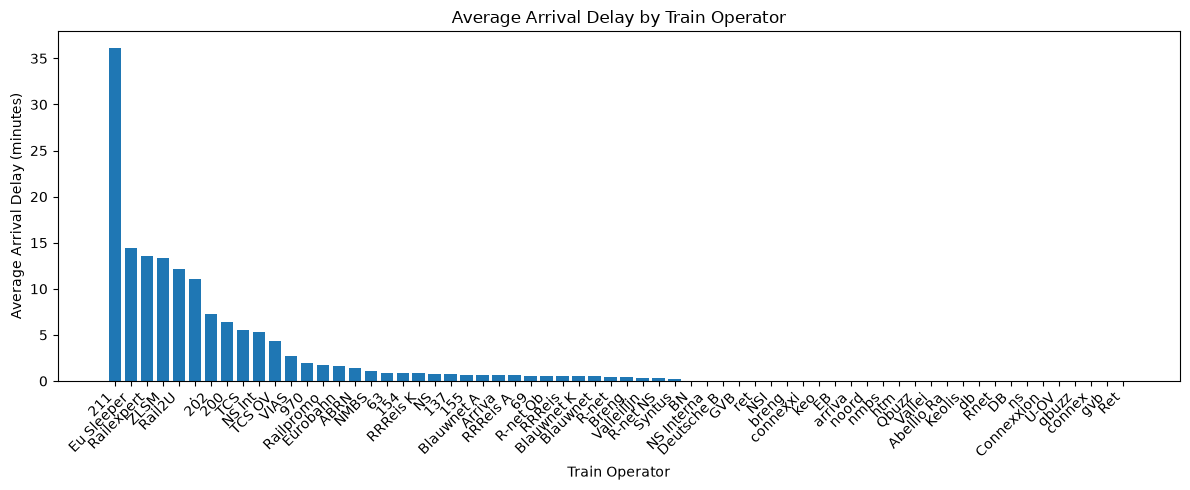

In [70]:
plt.figure(figsize=(12, 5))
plt.bar(df["company"], df["avg_delay"])
plt.title("Average Arrival Delay by Train Operator")
plt.xlabel("Train Operator")
plt.ylabel("Average Arrival Delay (minutes)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

##### 7.8 How many services were disrupted in different years?

In [71]:
df = db.sql("""
    SELECT
        YEAR("Service:Date") AS year,
        COUNT(DISTINCT "Service:RDT-ID") AS disrupted_services
    FROM services
    WHERE "Service:Maximum delay" > 0
       OR "Service:Partly cancelled" = TRUE
       OR "Service:Completely cancelled" = TRUE
    GROUP BY year
    ORDER BY year
""").df()

df

,year,disrupted_services
0,2019,1530040
1,2020,1556217
2,2021,1498298
3,2022,1622330
4,2023,1602143
5,2024,1605179
6,2025,1602266


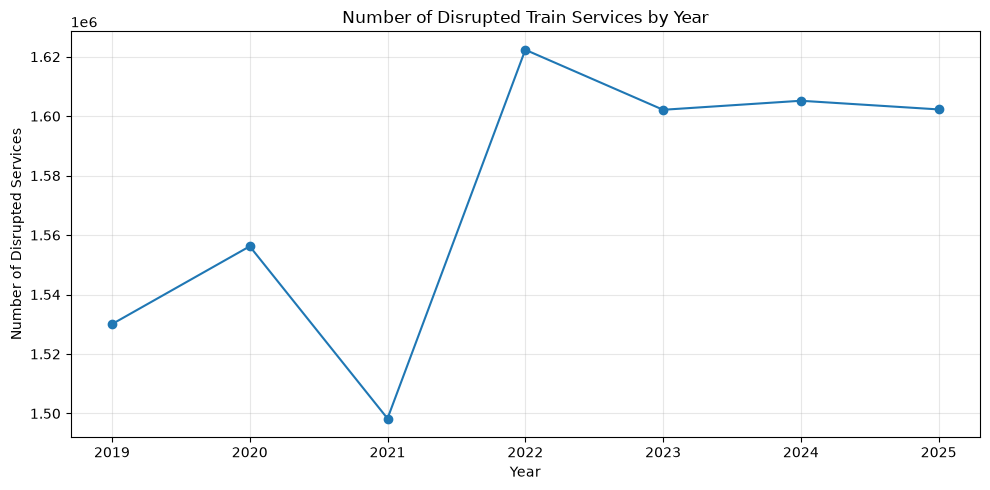

In [72]:
plt.figure(figsize=(10, 5))
plt.plot(df["year"], df["disrupted_services"], marker="o")
plt.title("Number of Disrupted Train Services by Year")
plt.xlabel("Year")
plt.ylabel("Number of Disrupted Services")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

##### 7.9 What fraction of all services were cancelled (Service:Completely cancelled) in different years?

In [73]:
df = db.sql("""
    SELECT
        YEAR("Service:Date") AS year,
        ROUND(
            COUNT(DISTINCT "Service:RDT-ID")
                FILTER (WHERE "Service:Completely cancelled" = TRUE)
            * 1.0 / NULLIF(COUNT(DISTINCT "Service:RDT-ID"), 0),
            4
        ) AS cancelled_fraction
    FROM services
    GROUP BY year
    ORDER BY year
""").df()

df

,year,cancelled_fraction
0,2019,0.0132
1,2020,0.0866
2,2021,0.0418
3,2022,0.0636
4,2023,0.0584
5,2024,0.0231
6,2025,0.0217


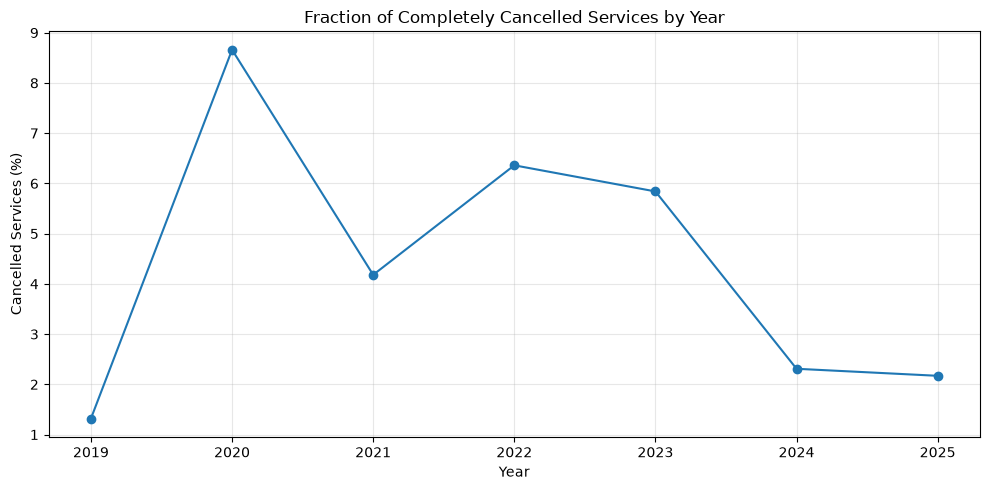

In [74]:
plt.figure(figsize=(10, 5))
plt.plot(df["year"], df["cancelled_fraction"] * 100, marker="o")
plt.title("Fraction of Completely Cancelled Services by Year")
plt.xlabel("Year")
plt.ylabel("Cancelled Services (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### 8. Create station_connections table

In [75]:
db.sql("""
    CREATE OR REPLACE TABLE station_connections AS
    WITH ordered_stops AS (
        SELECT
            "Service:RDT-ID",
            "Stop:Station code" AS start_station_code,
            LEAD("Stop:Station code") OVER (
                PARTITION BY "Service:RDT-ID"
                ORDER BY "Stop:Departure time" NULLS LAST,
                         "Stop:Arrival time" NULLS LAST,
                         "Stop:RDT-ID"
            ) AS end_station_code
        FROM services
    ),
    unique_distances AS (
        SELECT
            station,
            other_station,
            MIN(TRY_CAST(distance AS INTEGER)) AS distance
        FROM distances_long
        WHERE station < other_station
        GROUP BY station, other_station
    )
    SELECT DISTINCT
        o."Service:RDT-ID",
        o.start_station_code,
        o.end_station_code,
        d.distance
    FROM ordered_stops o
    LEFT JOIN unique_distances d
        ON LEAST(o.start_station_code, o.end_station_code) = d.station
       AND GREATEST(o.start_station_code, o.end_station_code) = d.other_station
    WHERE o.start_station_code IS NOT NULL
      AND o.end_station_code IS NOT NULL
      AND o.start_station_code <> o.end_station_code
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [76]:
db.sql("""SELECT * FROM station_connections LIMIT 5""")

┌────────────────┬────────────────────┬──────────────────┬──────────┐
│ Service:RDT-ID │ start_station_code │ end_station_code │ distance │
│     int64      │      varchar       │     varchar      │  int32   │
├────────────────┼────────────────────┼──────────────────┼──────────┤
│        5218830 │ HN                 │ PMO              │       18 │
│        5224045 │ BRN                │ HVS              │        7 │
│        5225463 │ KPN                │ ZLSH             │       10 │
│        5226377 │ HDE                │ NS               │        9 │
│        5227208 │ AVAT               │ NKK              │        5 │
└────────────────┴────────────────────┴──────────────────┴──────────┘

Calculate total distance of each train service

In [77]:
db.sql("""
    CREATE OR REPLACE TABLE service_lengths AS
    SELECT
        "Service:RDT-ID",
        CASE
            WHEN COUNT(*) = COUNT(distance)
            THEN SUM(distance)
        END AS total_distance
    FROM station_connections
    GROUP BY "Service:RDT-ID"
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Example routes

In [78]:
db.sql("""
    SELECT *
    FROM service_lengths
    WHERE total_distance IS NOT NULL
    ORDER BY total_distance DESC
    LIMIT 5
""")

┌────────────────┬────────────────┐
│ Service:RDT-ID │ total_distance │
│     int64      │     int128     │
├────────────────┼────────────────┤
│        7122512 │           2816 │
│       12609957 │           2794 │
│       12609771 │           2585 │
│        3907188 │           2317 │
│        3902549 │           2222 │
└────────────────┴────────────────┘

What is the largest distance between a pair of stations?

In [79]:
db.sql("""
    SELECT
        start_station_code,
        end_station_code,
        distance
    FROM station_connections
    WHERE distance IS NOT NULL
    ORDER BY distance DESC
    LIMIT 1
""")

┌────────────────────┬──────────────────┬──────────┐
│ start_station_code │ end_station_code │ distance │
│      varchar       │     varchar      │  int32   │
├────────────────────┼──────────────────┼──────────┤
│ VS                 │ STV              │      421 │
└────────────────────┴──────────────────┴──────────┘

Plot a histogram of inter-station distances run by trains.

In [80]:
df = db.sql("""
    SELECT
        CAST(FLOOR(distance / 5.0) * 5 AS INTEGER) AS distance_bin,
        COUNT(*) AS frequency
    FROM station_connections
    WHERE distance IS NOT NULL
    GROUP BY distance_bin
    ORDER BY distance_bin
""").df()

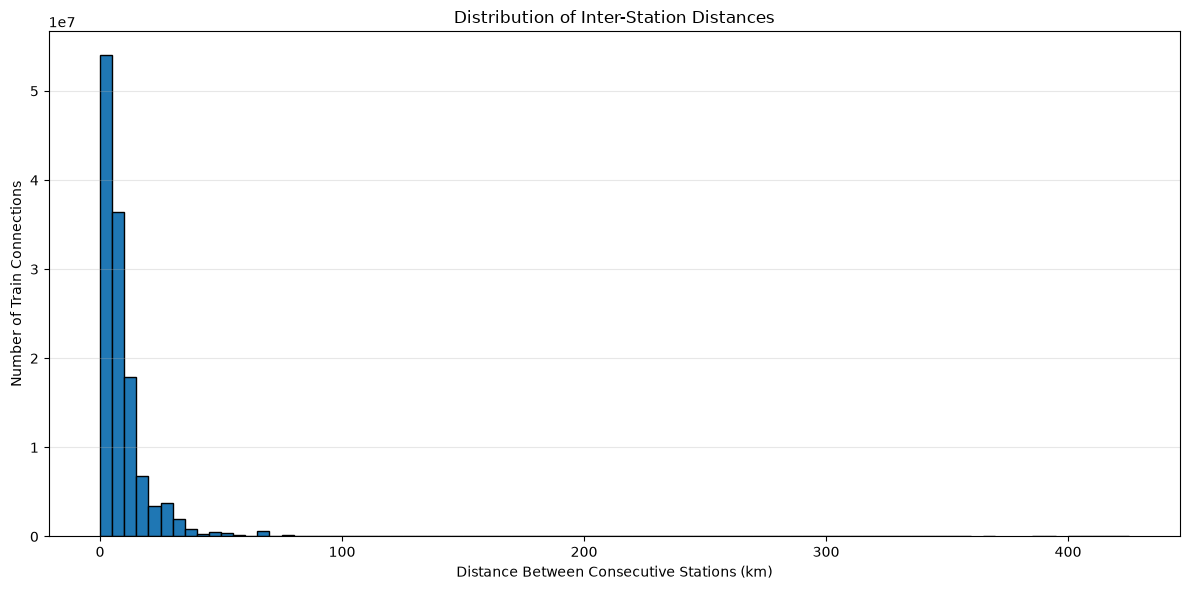

In [81]:
plt.figure(figsize=(12, 6))

plt.bar(df["distance_bin"], df["frequency"], width=5, align="edge", edgecolor="black")

plt.title("Distribution of Inter-Station Distances")
plt.xlabel("Distance Between Consecutive Stations (km)")
plt.ylabel("Number of Train Connections")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()